# Plotting with pandas

It is time to learn how to plot with our favorite data wrangling tool : pandas 🐼.

We will be using the open data powering https://www.rte-france.com/eco2mix website. 

The pre-processing of the data has been already done for you. All you need is to learn how read pickles from pandas!

![pickles](https://static.wikia.nocookie.net/rickandmorty/images/4/41/Pickle_rick_transparent_edgetrimmed.png)


## Exercise - setting up our (plotting) environment

In [1]:
# load pandas, matplotlib and setup your environment for bigger figures by default (check matplotlib's "rcParams")
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

plt.style.use('seaborn-v0_8') 
plt.rcParams["figure.figsize"] = (22, 8)
#ToDo

## Exercise : loading the data from a pickle file

In [2]:
# Load from the pickle file eco2mix (in the data folder) the dataframe and assign it to the variable df
df = pd.read_pickle('eco2mix.pkl')



df.sample(10) # take 10 samples at random


,Périmètre,Consommation,Thermique,Nucléaire,Eolien,Solaire,Hydraulique,Pompage,Bioénergies,Ech. physiques
DateTime,,,,,,,,,,
2014-02-23 16:45:00,Hauts-de-France,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-07-14 22:00:00,Grand-Est,3821.0,39.0,9709.0,110.0,0.0,1263.0,0.0,54.0,-7354.0
2013-02-28 15:30:00,Centre-Val de Loire,3192.0,82.0,9750.0,58.0,26.0,19.0,NaN,28.0,-6775.0
2016-10-12 23:30:00,Ile-de-France,8703.0,424.0,NaN,20.0,0.0,8.0,NaN,126.0,8125.0
2014-10-26 03:00:00,Bourgogne-Franche-Comté,1775.0,18.0,NaN,1.0,0.0,45.0,0.0,18.0,1691.0
2017-02-13 15:15:00,Normandie,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-07-12 17:00:00,Pays-de-la-Loire,2854.0,14.0,NaN,178.0,139.0,1.0,NaN,38.0,2485.0
2017-10-22 23:15:00,Grand-Est,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-10-13 08:15:00,PACA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Plotting with Matplotlib


##  Exercise -  Pie chart 

Choose a year in the data, and plot the share for each of the different energy sources, for example like this:

<img src="./img/pie.png" width=400px />


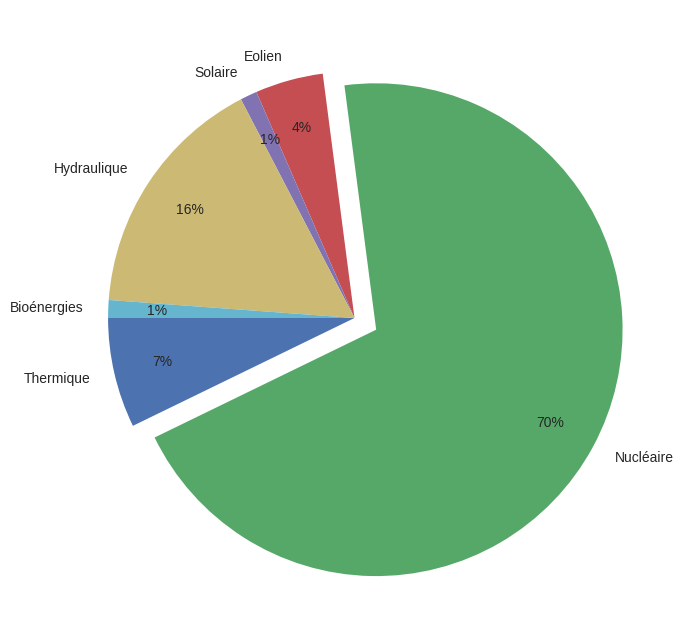

In [3]:
# Choose a year (ex: 2018) and plot the share that each of the different energy sources has in the total energy production:
df_2016 = df.loc['2016'].dropna()
explode = (0, 0.1, 0, 0, 0, 0)

cols = ['Thermique', 'Nucléaire', 'Eolien', 'Solaire', 'Hydraulique', 'Bioénergies']
bars = df_2016[cols]
values = df_2016[cols].sum()

plt.pie(values, labels=values.index, autopct='%1.0f%%', pctdistance= 0.8, labeldistance=1.1, startangle=180, explode=explode)
plt.show()
#ToDo

## Exercise :  Horizontal Bar

Use a horizontal bar chart instead of a pie to represent the previous data

_Tip: When possible, try to replace pie charts with horizontal bar_

<Axes: >

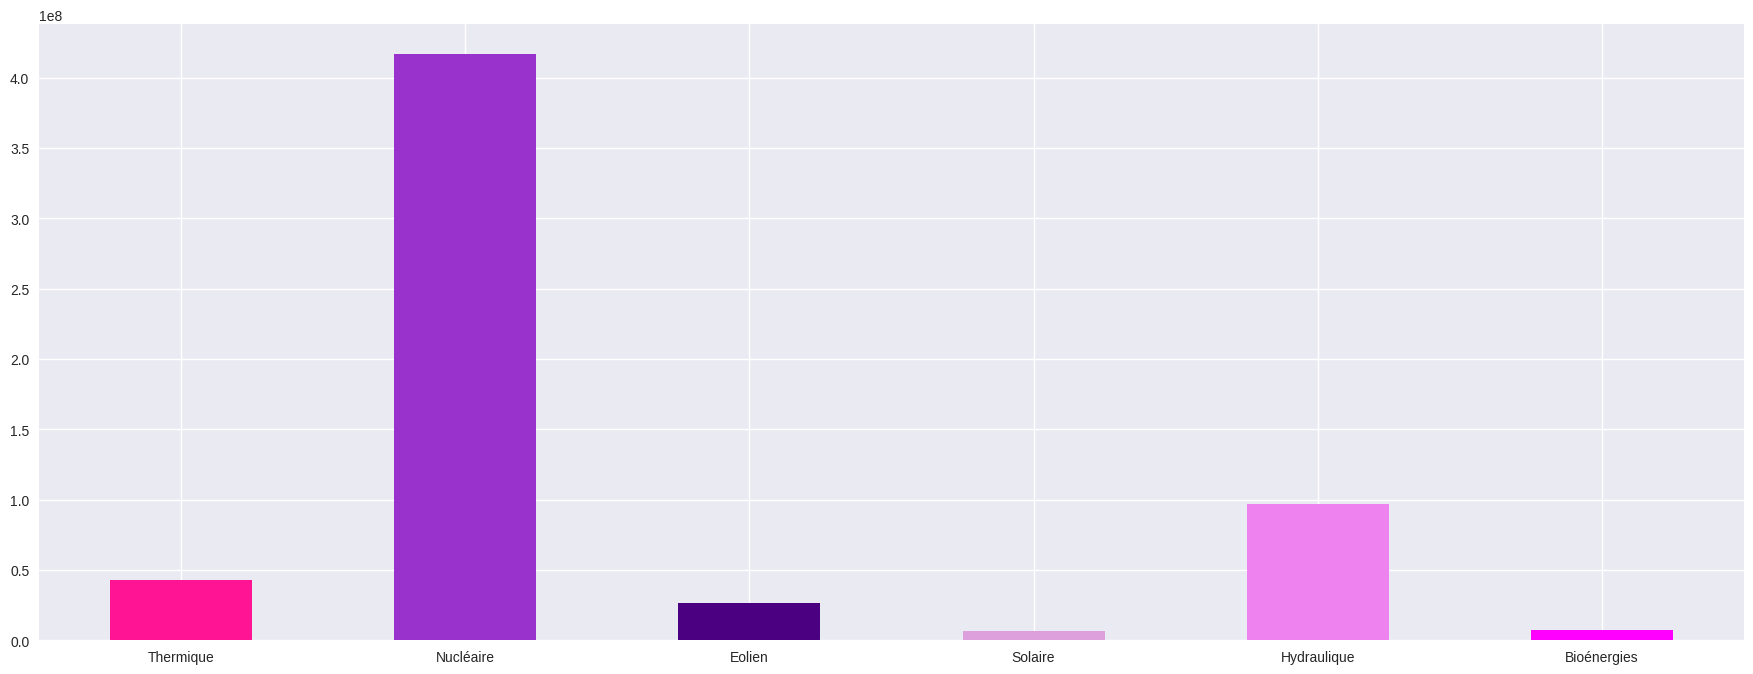

In [11]:
# When thinking about pie charts, give a try to horizontal bars.
colors = ['deeppink', 'darkorchid', 'indigo', 'plum', 'violet', 'magenta']
values.plot.bar(rot=0, color=colors)


#ToDo

## Exercise : Area chart

Go ahead and explore trends in the evolution of the energy production with the help of an area chart

<Axes: xlabel='DateTime'>

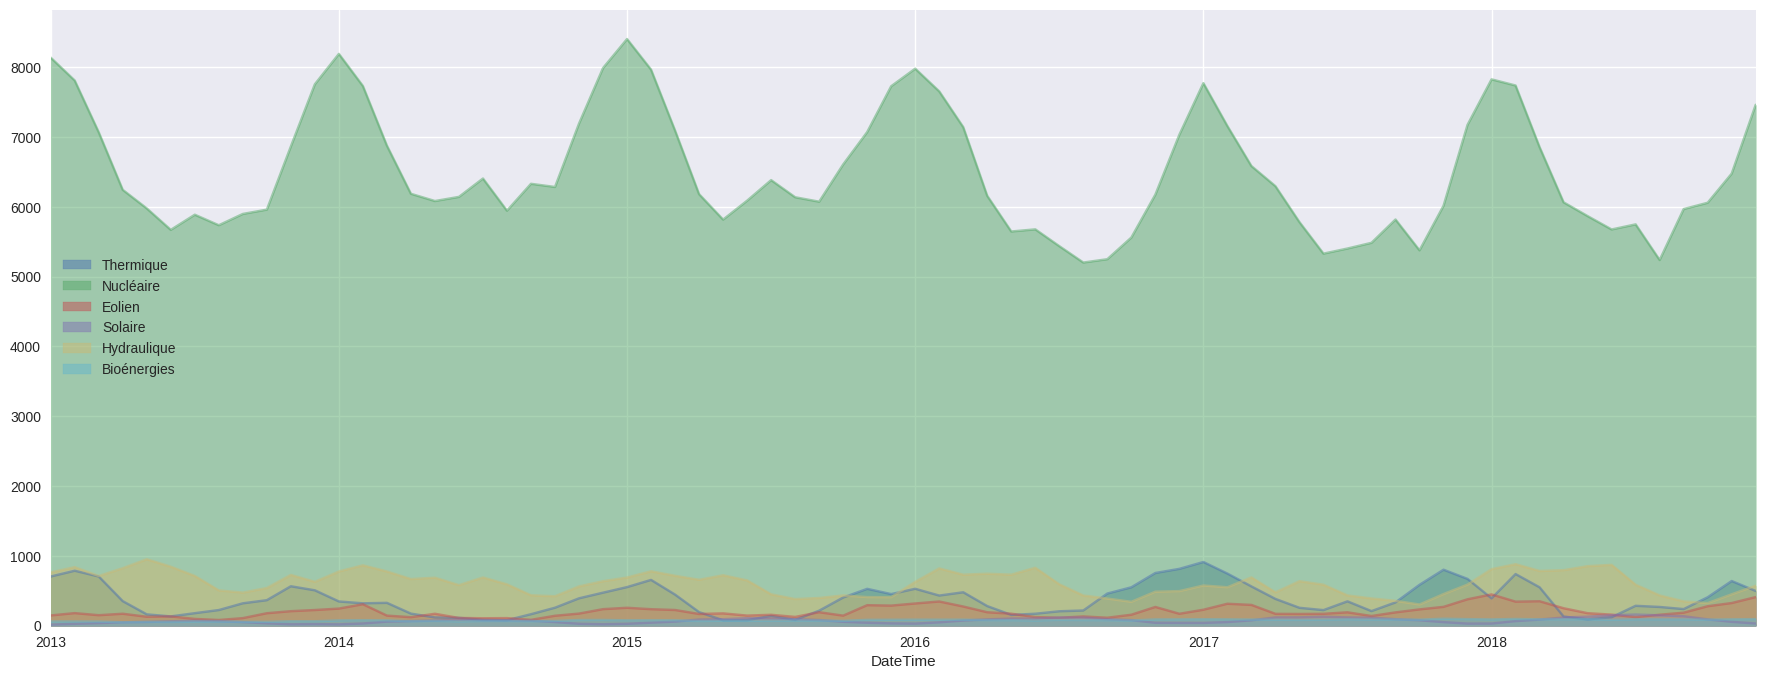

In [22]:
# Explore trends
df_cols = df[cols]
bars_daily = df_cols.resample("ME").mean()
bars_daily.plot.area(stacked=False)
#ToDo

## Exercise : Scatter Plot

Scatter plots are helpful to put in evidence relationships between two variables. Can you find a data relationships and make it visible with a plot ?

_Bonus: try Seaborn's joint plots_

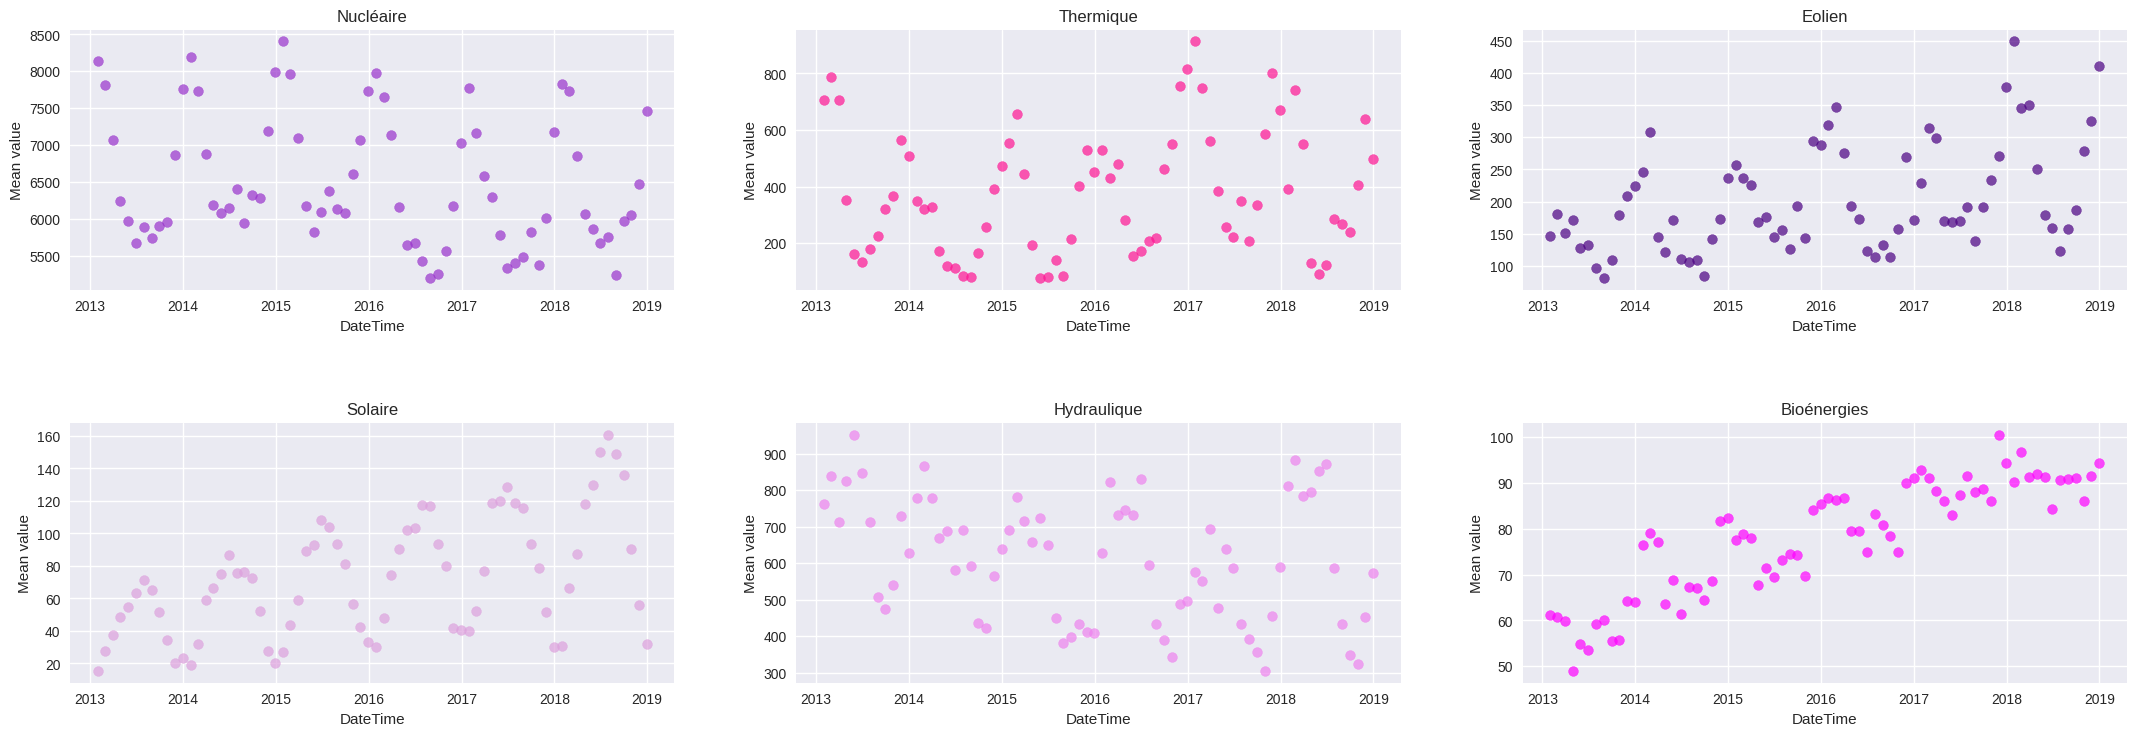

In [47]:

fig , ax = plt.subplots(2,3)
col_monthly = df_cols["Nucléaire"].resample("ME").mean()
ax[0,0].scatter(col_monthly.index, col_monthly.values, alpha=0.7, s=50, c='darkorchid')
ax[0,0].set_title("Nucléaire")
ax[0,0].set_ylabel("Mean value")
ax[0,0].set_xlabel("DateTime")

col_monthly = df_cols["Thermique"].resample("ME").mean()
ax[0,1].scatter(col_monthly.index, col_monthly.values, alpha=0.7, s=50, c='deeppink')
ax[0,1].set_title("Thermique")
ax[0,1].set_ylabel("Mean value")
ax[0,1].set_xlabel("DateTime")

col_monthly = df_cols["Eolien"].resample("ME").mean()
ax[0,2].scatter(col_monthly.index, col_monthly.values, alpha=0.7, s=50, c='indigo')
ax[0,2].set_title("Eolien")
ax[0,2].set_ylabel("Mean value") 
ax[0,2].set_xlabel("DateTime")

col_monthly = df_cols["Solaire"].resample("ME").mean()
ax[1,0].scatter(col_monthly.index, col_monthly.values, alpha=0.7, s=50, c='plum')
ax[1,0].set_title("Solaire")
ax[1,0].set_ylabel("Mean value")
ax[1,0].set_xlabel("DateTime")

col_monthly = df_cols["Hydraulique"].resample("ME").mean()
ax[1,1].scatter(col_monthly.index, col_monthly.values, alpha=0.7, s=50, c='violet')
ax[1,1].set_title("Hydraulique")
ax[1,1].set_xlabel("DateTime")
ax[1,1].set_ylabel("Mean value")

col_monthly = df_cols["Bioénergies"].resample("ME").mean()
ax[1,2].scatter(col_monthly.index, col_monthly.values, alpha=0.7, s=50, c='magenta')
ax[1,2].set_title("Bioénergies")
ax[1,2].set_xlabel("DateTime")
ax[1,2].set_ylabel("Mean value")


plt.tight_layout(pad=3.0, h_pad=5.0, w_pad=5.0)
plt.show()


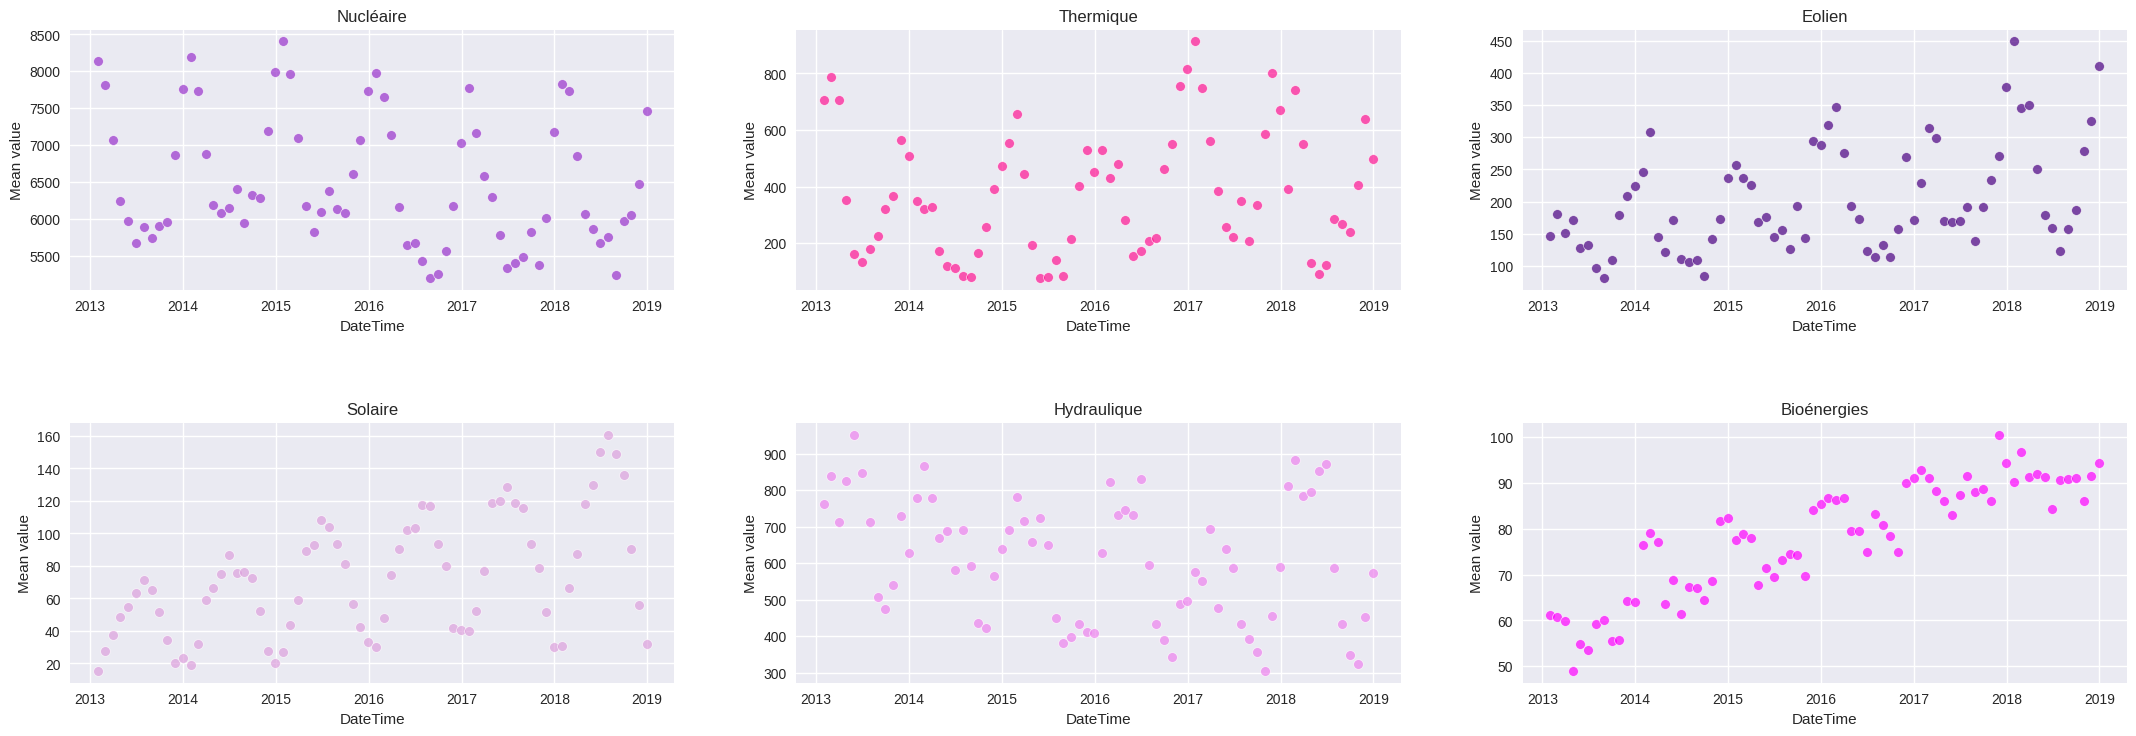

In [51]:
# let's use the amazing Seaborn library to plot even more insightfull scatter plots:
import seaborn as sns # make sure you installed the library with pip or conda!

# create a joint plot using Seaborn:
import seaborn as sns

fig, ax = plt.subplots(2, 3)

cols_colors = [
    ("Nucléaire", 'darkorchid', ax[0,0]),
    ("Thermique", 'deeppink', ax[0,1]),
    ("Eolien", 'indigo', ax[0,2]),
    ("Solaire", 'plum', ax[1,0]),
    ("Hydraulique", 'violet', ax[1,1]),
    ("Bioénergies", 'magenta', ax[1,2]),
]
# sns.scatterplot(data(numeric),x(from data),y(from data), ax(the axis from subplot)
for col_name, color, axis in cols_colors:
    col_monthly = df_cols[col_name].resample("ME").mean().reset_index()
    sns.scatterplot(data=col_monthly, x="DateTime", y=col_name, 
                     alpha=0.7, s=50, color=color, ax=axis)
    axis.set_title(col_name)
    axis.set_ylabel("Mean value")
    axis.set_xlabel("DateTime")

plt.tight_layout(pad=3.0, h_pad=5.0, w_pad=5.0)
plt.show()
#ToDo

# Plotting with Plotly (optional)

In order to go further you can start exploring an alternative ploting library: Plotly.

Two possible ways of using plotly with pandas :
 - https://plotly.com/python/pandas-backend/
 - https://github.com/santosjorge/cufflinks
 - https://coderzcolumn.com/tutorials/data-science/cufflinks-how-to-create-plotly-charts-from-pandas-dataframe-with-one-line-of-code
 
Repeat the previous exercises using the Plotly/Cufflinks backend for Pandas. 

Which library do you prefer ? Which plotly integration works better ?

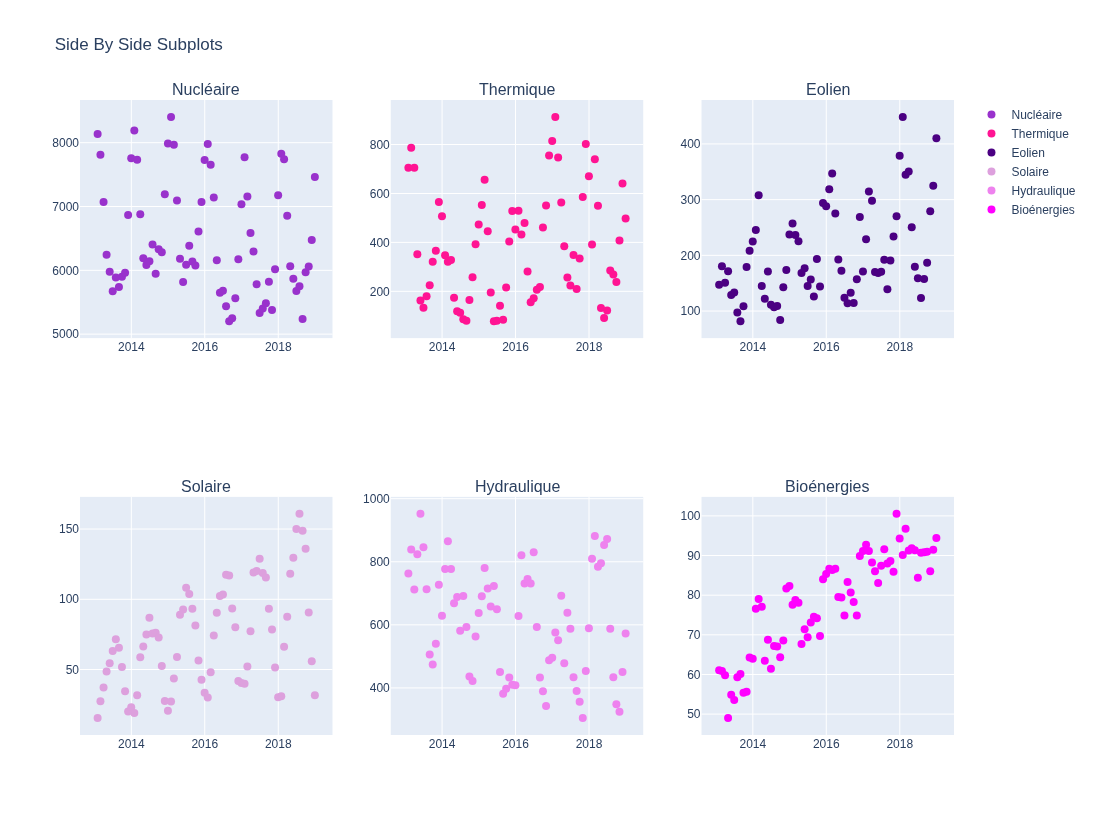

In [67]:
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(rows=2, cols=3, subplot_titles=["Nucléaire", "Thermique", "Eolien", "Solaire", "Hydraulique", "Bioénergies"])

cols_positions = [
    ("Nucléaire", 1, 1,'darkorchid'),
    ("Thermique", 1, 2,'deeppink'),
    ("Eolien", 1, 3,'indigo'),
    ("Solaire", 2, 1,'plum'),
    ("Hydraulique", 2, 2,'violet'),
    ("Bioénergies", 2, 3,'magenta'),
]

for col_name, row, col, c in cols_positions:
    col_monthly = df_cols[col_name].resample("ME").mean().reset_index()
    fig.add_trace(
        go.Scatter(x=col_monthly["DateTime"], y=col_monthly[col_name], 
                    mode="markers", name=col_name,marker=dict(color=c, size=8)),
        row=row, col=col
    )

fig.update_layout(height=800, width=1800,title_text="Side By Side Subplots")
fig.show()